In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split,KFold
from sklearn.metrics import root_mean_squared_error
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

In [5]:
train=pd.read_csv("../data/raw/Train.csv")
test=pd.read_csv("../data/raw/Test.csv")


In [6]:
train["time"]=pd.to_datetime(train["time"])
test["time"]=pd.to_datetime(test["time"])

In [7]:
train["month"]=train["time"].dt.month
test["month"]=test["time"].dt.month

In [8]:
train["month_sin"]=np.sin(2 * np.pi * train["month"]/12)
train["month_cos"]=np.cos(2 * np.pi * train["month"]/12)

test["month_sin"]=np.sin(2* np.pi * test["month"]/12)
test["month_cos"]=np.cos(2 * np.pi *test["month"]/12)


In [9]:
X=train.drop(columns=["sample_id","target","time"])
y=train["target"]

In [10]:
print(X.columns)

Index(['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t',
       'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month'],
      dtype='str')


In [11]:
X_train,X_valid,y_train,y_valid=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [12]:
model=LGBMRegressor(random_state=42)
model.fit(X_train,y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007976 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184


,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [13]:
predictions=model.predict(X_valid)

In [14]:
rmse = root_mean_squared_error(
    y_valid,
    predictions
)

print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 0.5127


In [15]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
1,lon,633
0,lat,621
2,TWS_t,531
5,SPEI_06_t,282
9,month_cos,210
8,month_sin,160
4,SPEI_03_t,160
6,SPEI_12_t,131
10,month,125
3,SPEI_01_t,78


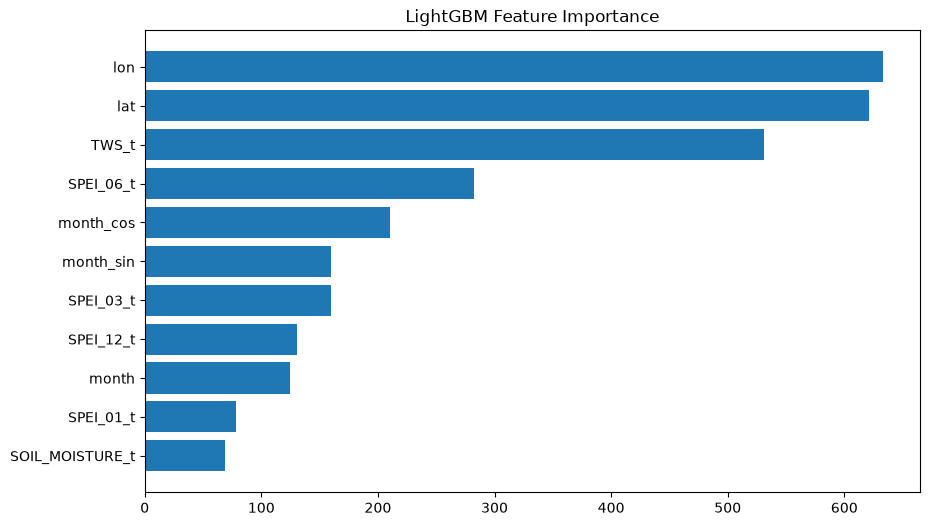

In [16]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("LightGBM Feature Importance")

plt.show()

In [17]:
model = LGBMRegressor(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007451 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4992


In [18]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007080 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4923


In [19]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007571 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4569


In [20]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    random_state=42,
    max_depth=7
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007211 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [21]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    random_state=42,
    max_depth=10
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007325 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4599


In [22]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    random_state=42,
    max_depth=15
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007320 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4569


In [23]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    random_state=42,
    max_depth=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007375 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Validation RMSE: 0.4569


In [24]:
best_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.15,
    num_leaves=127,
    max_depth=15,
    random_state=42
)

best_model.fit(X, y)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009832 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1949
[LightGBM] [Info] Number of data points in the train set: 2154021, number of used features: 11
[LightGBM] [Info] Start training from score 0.112504


,num_leaves,127
,max_depth,15
,learning_rate,0.15
,n_estimators,300
,random_state,42
,boosting_type,'gbdt'
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [25]:

X_test = test[X.columns]

In [26]:
print(X.columns.tolist())
print(X_test.columns.tolist())

['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t', 'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month']
['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t', 'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month']


In [27]:
print("Train özellik sayısı:", len(X.columns))
print(X.columns)

print("\nTest özellik sayısı:", len(X_test.columns))
print(X_test.columns)

Train özellik sayısı: 11
Index(['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t',
       'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month'],
      dtype='str')

Test özellik sayısı: 11
Index(['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t',
       'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month'],
      dtype='str')


In [28]:
test_predictions = best_model.predict(X_test)

In [29]:
sample_submission = pd.read_csv("../data/raw/SampleSubmission.csv")

submission = sample_submission.copy()

submission["Target"] = test_predictions   # Büyük T

submission.head()

,ID,Target
0,20150901_-55.5_-68.5,0.091789
1,20150901_-55.5_-67.5,0.002663
2,20150901_-54.5_-71.5,0.450814
3,20150901_-54.5_-70.5,0.336970
4,20150901_-54.5_-69.5,0.220454


In [30]:
print(submission.columns)

Index(['ID', 'Target'], dtype='str')


In [31]:
submission.to_csv(
    "../submissions/submission_v1.csv",
    index=False
)

In [32]:
check = pd.read_csv("../submissions/submission_v1.csv")

print(check.head())
print(check.columns)

                     ID    Target
0  20150901_-55.5_-68.5  0.091789
1  20150901_-55.5_-67.5  0.002663
2  20150901_-54.5_-71.5  0.450814
3  20150901_-54.5_-70.5  0.336970
4  20150901_-54.5_-69.5  0.220454
Index(['ID', 'Target'], dtype='str')


In [33]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]
    model = LGBMRegressor(
        n_estimators=300,
        learning_rate=0.15,
        num_leaves=127,
        random_state=42
    )

    model.fit(X_train, y_train)

    preds = model.predict(X_val)

    rmse = root_mean_squared_error(y_val, preds)

    scores.append(rmse)

    print(f"Fold {fold}: {rmse:.4f}")

print(f"\nAverage RMSE: {np.mean(scores):.4f}")
print(f"Std RMSE: {np.std(scores):.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009526 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1948
[LightGBM] [Info] Number of data points in the train set: 1723216, number of used features: 11
[LightGBM] [Info] Start training from score 0.113184
Fold 1: 0.4564
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011150 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1949
[LightGBM] [Info] Number of data points in the train set: 1723217, number of used features: 11
[LightGBM] [Info] Start training from score 0.112200
Fold 2: 0.4568
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008555 seconds.
You can set `force_row_wise=true` to remove the ov